# Tarea 2 · Parte 2 — Evaluación, comparación de modelos y extracción estructurada

**Pregunta guía:** ¿Pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

Este notebook usa **solo** los archivos recolectados en la Parte 1 (`01_extraccion.ipynb`):

| Paso | Qué se hace | Modelos |
|---|---|---|
| 1 | Muestra fija de **10 documentos** y **10 clips** con transcripción manual (`texto_referencia`) | — |
| 2 | Línea base | PaddleOCR 3.7 base · faster-whisper `small` (CPU, int8) |
| 3 | Modelos alternativos sobre **las mismas** muestras | Tesseract 5 (`spa`) · Whisper large-v3-turbo (Parte 1) · Qwen3-ASR 0.6B (Sesión 13) |
| 4 | Extracción estructurada con LLM + auditoría humana de 20 casos | Gemini (API) u Ollama local |
| 5 | Casos difíciles, tabla comparativa y decisión | — |

**Reglas que sigo:** las configuraciones de todos los modelos se fijan **antes** de ver las métricas; todos los modelos se evalúan sobre los mismos 10 + 10 archivos;
las referencias son transcripciones humanas (no salidas de otro modelo).

### Instalación (una vez, en la terminal, dentro de `tarea_2`)
```
.venv\Scripts\python.exe -m pip install pytesseract "transformers>=5.16" accelerate google-genai python-dotenv
winget install UB-Mannheim.TesseractOCR
```
Para el LLM: crear un archivo `tarea_2/.env` (ya está en `.gitignore`) con la línea `GEMINI_API_KEY=tu_clave` (clave gratis en aistudio.google.com).

In [4]:
import os, re, json, time, random, warnings, hashlib, platform
from datetime import date
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"

import torch                     # en Windows, torch antes que paddle
import numpy as np
import pandas as pd
import jiwer
import voz
from voz import SR, cargar_audio, normalizar

BASE = Path.cwd()
DATOS = BASE / "datos"
RAW = DATOS / "raw"
AUDIO = RAW / "audio"
REF = RAW / "referencias"; REF.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 90)

documentos = pd.read_csv(DATOS / "documentos.csv", dtype={"id": str}).fillna({"texto_ocr": "", "texto_referencia": ""})
transcripciones = pd.read_csv(DATOS / "transcripciones.csv", dtype={"id": str}).fillna({"texto_asr": "", "texto_referencia": ""})
ocr_crudo = pd.read_csv(RAW / "ocr_crudo.csv", dtype={"id": str}).fillna({"texto_ocr_crudo": ""})
inventario = pd.read_csv(AUDIO / "inventario_clips.csv", dtype={"id": str}).fillna({"texto_oficial": ""})
# Misma seudonimización de la Parte 1: se aplica a TODA salida de modelo antes de medir y de guardar
reemplazos = dict(pd.read_csv(RAW / "reemplazos_privados.csv", dtype=str, sep=None, engine="python",
                              encoding="utf-8-sig").dropna().values)
PRIVADOS = {"doc_014"}
def seud(texto, i=""):
    t = texto or ""
    for nombre, s in reemplazos.items():
        t = voz.seudonimizar(t, {nombre.strip(): s})
    t = re.sub(r"\bDNI\W{0,3}\d{8}\b", "[DNI]", t, flags=re.I)
    if i in PRIVADOS:
        t = re.sub(r"\b9\d{2}[\s-]?\d{3}[\s-]?\d{3}\b", "[TELEFONO]", t)
    return t

print("Python", platform.python_version(), "· torch", torch.__version__)
print(f"Documentos: {len(documentos)} · Clips: {len(transcripciones)} ({transcripciones.duracion_seg.sum() / 60:.1f} min)")

Python 3.12.15 · torch 2.14.1+cpu
Documentos: 25 · Clips: 24 (32.2 min)


## 1. Muestra de evaluación (fijada antes de medir)

La muestra se eligió **al azar con semilla fija (2026)** y quedó guardada con fecha en `modelos/config_evaluacion.json` **antes** de calcular cualquier métrica:
- **Documentos (10):** 3 impresos, 3 fotos y 4 manuscritos, sorteados entre los que tienen ≤ 1 500 caracteres de OCR
  (transcribir a mano un periódico entero no es viable). El criterio es el largo, no el error del OCR.
- **Clips (10):** las 3 entrevistas más cortas de Wikimedia Commons (calle, con ruido) + 7 clips de lectura de OpenSLR 73 sorteados.

### Cómo se hicieron las referencias manuales
- **Documentos:** transcribí cada imagen a mano en `datos/raw/referencias/doc_XXX.txt`, **copiando la ortografía original** (p. ej. "estranjero", "sufrajios")
  y escribiendo solo lo que se ve (sin completar palabras cortadas). En `doc_014` escribí `[PERSONA_1]` y `[TELEFONO]` en lugar de los datos del particular,
  porque la referencia se publica; por la misma razón, la salida de **todos** los modelos se seudonimiza igual antes de medir y guardar.
- **Entrevistas de Commons:** transcritas a mano escuchando el audio.
- **OpenSLR 73:** el dataset trae la transcripción humana del texto leído. La usé como punto de partida y **la verifiqué escuchando cada clip**, corrigiendo
  donde el lector se apartó del texto. No se usó ninguna salida de modelo como referencia.

In [5]:
# Muestra fijada antes de medir (modelos/config_evaluacion.json, semilla 2026)
cfg = json.loads((BASE / "modelos/config_evaluacion.json").read_text(encoding="utf-8"))
DOCS_EVAL_IDS = cfg["muestra_docs"]
CLIPS_EVAL_IDS = cfg["muestra_audio"]
assert set(DOCS_EVAL_IDS) <= set(ocr_crudo["id"]), "Algún documento de evaluación no está en el OCR de la Parte 1"

inv = inventario.set_index("id")
print("Fijada el", cfg["fecha"], "con semilla", cfg["semilla"])
print("Documentos de evaluación:", DOCS_EVAL_IDS)
print("Clips de evaluación:     ", CLIPS_EVAL_IDS)
display(inv.loc[CLIPS_EVAL_IDS, ["fuente", "origen", "duracion_seg"]])
print(f"Audio de evaluación: {inv.loc[CLIPS_EVAL_IDS, 'duracion_seg'].sum() / 60:.1f} min")

Fijada el 2026-10-24 con semilla 2026
Documentos de evaluación: ['doc_008', 'doc_002', 'doc_007', 'doc_014', 'doc_015', 'doc_016', 'doc_024', 'doc_020', 'doc_025', 'doc_022']
Clips de evaluación:      ['clip_007', 'clip_002', 'clip_004', 'clip_021', 'clip_016', 'clip_020', 'clip_024', 'clip_009', 'clip_022', 'clip_018']


,fuente,origen,duracion_seg
id,,,
clip_007,Wikimedia Commons,aurora_coronado.ogg,18.7
clip_002,Wikimedia Commons,agustino_1.ogg,20.5
clip_004,Wikimedia Commons,agustino_2.ogg,69.7
clip_021,OpenSLR 73,hablante pef_00610,79.2
clip_016,OpenSLR 73,hablante pem_02121,76.6
clip_020,OpenSLR 73,hablante pem_02484,77.3
clip_024,OpenSLR 73,hablante pem_07508,79.7
clip_009,OpenSLR 73,hablante pef_02121,78.0
clip_022,OpenSLR 73,hablante pem_04310,77.2


Audio de evaluación: 10.9 min


In [6]:
# Crea las plantillas de referencia (solo si no existen; nunca sobrescribe lo que ya escribí a mano)
for d in DOCS_EVAL_IDS:
    p = REF / f"{d}.txt"
    if not p.exists():
        p.write_text("", encoding="utf-8")
for c in CLIPS_EVAL_IDS:
    p = REF / f"{c}.txt"
    if not p.exists():
        p.write_text(inv.loc[c, "texto_oficial"] if inv.loc[c, "fuente"] == "OpenSLR 73" else "", encoding="utf-8")

def leer_ref(i):
    return (REF / f"{i}.txt").read_text(encoding="utf-8").strip()

vacias = [i for i in DOCS_EVAL_IDS + CLIPS_EVAL_IDS if not leer_ref(i)]
if vacias:
    print("Faltan referencias manuales. Abre y completa en VS Code estos archivos de datos/raw/referencias/:")
    for i in vacias:
        print("  ", f"{i}.txt")
    raise SystemExit("Completa las referencias y vuelve a ejecutar esta celda.")
print("Las 20 referencias están completas.")

Las 20 referencias están completas.


In [7]:
# Las referencias pasan a la columna texto_referencia (vacía en los demás registros)
documentos["texto_referencia"] = documentos["id"].map(lambda i: leer_ref(i) if i in DOCS_EVAL_IDS else "")
transcripciones["texto_referencia"] = transcripciones["id"].map(lambda i: leer_ref(i) if i in CLIPS_EVAL_IDS else "")
documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)
print("texto_referencia guardado:", (documentos.texto_referencia != "").sum(), "documentos ·",
      (transcripciones.texto_referencia != "").sum(), "clips")

texto_referencia guardado: 10 documentos · 10 clips


### Normalización (la misma para referencias y para todos los modelos)
- `voz.normalizar` de la Sesión 13: minúsculas, sin puntuación, espacios simples; **las tildes se conservan**.
- OCR: se unen las palabras cortadas con guion al final de línea ("igualmen-/te" → "igualmente") y los saltos de línea pasan a espacios.
- ASR: se quitan las marcas `[HABLANTE_n]` y los seudónimos `[PERSONA_n]`, que no son palabras habladas.

In [8]:
def norm_ocr(t):
    t = re.sub(r"-\s*\n\s*", "", t or "")
    return normalizar(t.replace("\n", " "))

def norm_asr(t):
    t = re.sub(r"\[(HABLANTE|PERSONA)_\d+\]|\[(DNI|TELEFONO)\]", " ", t or "")
    return normalizar(t)

def cer_1(ref, hip):
    return jiwer.cer(norm_ocr(ref), norm_ocr(hip) or "∅")

def wer_1(ref, hip):
    return jiwer.wer(norm_asr(ref), norm_asr(hip) or "∅")

print(norm_ocr("Por eso la falta de cri-\nmen, y los vicios"))
print(norm_asr("[HABLANTE_1] Cuando llegué a Lima, ¿sabes? [HABLANTE_2] Sí."))

por eso la falta de crimen y los vicios
cuando llegué a lima sabes sí


## 2. Documentos: PaddleOCR (línea base) vs. Tesseract

- **Línea base:** el texto de PaddleOCR de la Parte 1 (configuración base, sin personalizar). Se usa el texto **crudo**, antes de seudonimizar.
- **Alternativa:** Tesseract 5 con el modelo `spa` (LSTM), `--psm 3` (página automática), sobre la **misma** imagen preprocesada de la Parte 1.
  Es el OCR clásico de código abierto y el que sugiere el enunciado; no necesita GPU.

In [9]:
%pip install -q pytesseract "transformers>=5.16" accelerate google-genai python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [10]:
import pytesseract
from PIL import Image

TESS = Path(r"C:\Program Files\Tesseract-OCR\tesseract.exe")
if TESS.exists():
    pytesseract.pytesseract.tesseract_cmd = str(TESS)
TESSDATA = RAW / "tessdata"; TESSDATA.mkdir(exist_ok=True)
if not (TESSDATA / "spa.traineddata").exists():          # modelo de español (licencia Apache 2.0)
    import requests
    url = "https://github.com/tesseract-ocr/tessdata_fast/raw/main/spa.traineddata"
    (TESSDATA / "spa.traineddata").write_bytes(requests.get(url, timeout=120).content)
os.environ["TESSDATA_PREFIX"] = str(TESSDATA)        # carpeta con spa.traineddata (en Windows, sin comillas)
TESS_CONFIG = "--psm 3"
MODELO_TESS = f"Tesseract {pytesseract.get_tesseract_version()} (spa, psm 3)"
print(MODELO_TESS)

PROC = RAW / "documentos" / "proc"
ocr_base = ocr_crudo.set_index("id")
filas = []
for d in DOCS_EVAL_IDS:
    tipo = ocr_base.loc[d, "tipo"]
    ref = leer_ref(d)
    t0 = time.perf_counter()
    tess = seud(pytesseract.image_to_string(Image.open(PROC / f"{d}.png"), lang="spa", config=TESS_CONFIG), d)
    seg_tess = time.perf_counter() - t0
    paddle_txt = seud(ocr_base.loc[d, "texto_ocr_crudo"], d)
    filas += [
        {"modalidad": "documento", "id": d, "grupo": tipo, "modelo": "PaddleOCR (base)",
         "texto": paddle_txt, "error": cer_1(ref, paddle_txt),
         "segundos": ocr_base.loc[d, "segundos_ocr"]},
        {"modalidad": "documento", "id": d, "grupo": tipo, "modelo": "Tesseract (spa)",
         "texto": tess, "error": cer_1(ref, tess), "segundos": round(seg_tess, 2)},
    ]
    print(f"{d} [{tipo:<10}] CER PaddleOCR {filas[-2]['error']:.2f} · Tesseract {filas[-1]['error']:.2f}")
comp_ocr = pd.DataFrame(filas)

Tesseract 5.4.0.20240606 (spa, psm 3)
doc_008 [impreso   ] CER PaddleOCR 0.05 · Tesseract 0.78
doc_002 [impreso   ] CER PaddleOCR 0.44 · Tesseract 1.00
doc_007 [impreso   ] CER PaddleOCR 0.00 · Tesseract 0.02
doc_014 [foto      ] CER PaddleOCR 0.03 · Tesseract 0.26
doc_015 [foto      ] CER PaddleOCR 0.07 · Tesseract 1.00
doc_016 [foto      ] CER PaddleOCR 0.36 · Tesseract 0.85
doc_024 [manuscrito] CER PaddleOCR 0.27 · Tesseract 0.62
doc_020 [manuscrito] CER PaddleOCR 0.32 · Tesseract 0.32
doc_025 [manuscrito] CER PaddleOCR 0.14 · Tesseract 0.69
doc_022 [manuscrito] CER PaddleOCR 0.09 · Tesseract 0.50


In [11]:
def cer_corpus(df):
    "CER agregado: errores totales / caracteres totales de la referencia (no promedio de promedios)."
    refs = [norm_ocr(leer_ref(i)) for i in df["id"]]
    hips = [norm_ocr(t) or "∅" for t in df["texto"]]
    return jiwer.cer(refs, hips)

tabla_ocr = (comp_ocr.groupby(["modelo", "grupo"]).apply(cer_corpus).unstack("grupo")[["impreso", "foto", "manuscrito"]])
tabla_ocr["TOTAL (10 docs)"] = comp_ocr.groupby("modelo").apply(cer_corpus)
tabla_ocr["seg/doc"] = comp_ocr.groupby("modelo")["segundos"].mean()
(tabla_ocr * [100, 100, 100, 100, 1]).round(1).rename_axis("CER % por tipo")

grupo,impreso,foto,manuscrito,TOTAL (10 docs),seg/doc
CER % por tipo,,,,,
PaddleOCR (base),8.2,10.7,23.4,13.9,39.8
Tesseract (spa),36.8,64.2,52.0,48.5,1.9


## 3. Audio: faster-whisper `small` (línea base) vs. Whisper turbo vs. Qwen3-ASR

| Modelo | Por qué | Configuración (fijada antes de medir) |
|---|---|---|
| faster-whisper **small** | línea base del enunciado | CPU, int8, `language="es"`, beam 5, VAD |
| faster-whisper **large-v3-turbo** | el modelo de la Parte 1 | mismo texto de la Parte 1 (sin marcas de hablante) |
| **Qwen3-ASR 0.6B** | otra familia de modelo (Alibaba), Sesión 13 | `voz.Transcriptor("qwen3-asr-0.6b")`, CPU, `idioma="es"`, tramos por VAD |

**Latencia:** factor de tiempo real (RTF) = segundos de procesamiento / segundos de audio. RTF < 1 es más rápido que tiempo real.

In [12]:
from faster_whisper import WhisperModel
small = WhisperModel("small", device="cpu", compute_type="int8")

def transcribir_small(x):
    segs, _ = small.transcribe(x, language="es", beam_size=5, vad_filter=True)
    return " ".join(s.text.strip() for s in segs)

turbo = transcripciones.set_index("id")
filas = []
for c in CLIPS_EVAL_IDS:
    x = cargar_audio(AUDIO / f"{c}.wav"); dur = len(x) / SR
    ref = leer_ref(c)
    t0 = time.perf_counter(); txt = seud(transcribir_small(x)); seg = time.perf_counter() - t0
    filas.append({"modalidad": "audio", "id": c, "grupo": inv.loc[c, "fuente"], "modelo": "faster-whisper small (base)",
                  "texto": txt, "error": wer_1(ref, txt), "segundos": round(seg, 2), "rtf": round(seg / dur, 3)})
    filas.append({"modalidad": "audio", "id": c, "grupo": inv.loc[c, "fuente"], "modelo": "faster-whisper large-v3-turbo",
                  "texto": turbo.loc[c, "texto_asr"], "error": wer_1(ref, turbo.loc[c, "texto_asr"]),
                  "segundos": inv.loc[c, "segundos_asr"], "rtf": round(inv.loc[c, "segundos_asr"] / dur, 3)})
    print(f"{c} WER small {filas[-2]['error']:.2f} · turbo {filas[-1]['error']:.2f} · RTF small {filas[-2]['rtf']:.2f}")
comp_asr = pd.DataFrame(filas)

clip_007 WER small 0.35 · turbo 0.12 · RTF small 0.76
clip_002 WER small 0.60 · turbo 0.56 · RTF small 0.31
clip_004 WER small 0.12 · turbo 0.08 · RTF small 0.56
clip_021 WER small 0.08 · turbo 0.10 · RTF small 0.56
clip_016 WER small 0.03 · turbo 0.03 · RTF small 0.45
clip_020 WER small 0.08 · turbo 0.05 · RTF small 0.51
clip_024 WER small 0.05 · turbo 0.02 · RTF small 0.50
clip_009 WER small 0.02 · turbo 0.02 · RTF small 0.67
clip_022 WER small 0.09 · turbo 0.04 · RTF small 0.58
clip_018 WER small 0.10 · turbo 0.02 · RTF small 0.55


In [13]:
# Modelo alternativo de otra familia: Qwen3-ASR 0.6B (si no carga en esta laptop, MMS de Meta como respaldo)
try:
    alt = voz.Transcriptor("qwen3-asr-0.6b", device="cpu")
    MODELO_ALT = "Qwen3-ASR 0.6B"
except Exception as e:
    print("Qwen3-ASR no disponible (", type(e).__name__, e, ") → uso MMS-1b-all (spa)")
    alt = voz.Transcriptor("mms", device="cpu", idioma_mms="spa")
    MODELO_ALT = "MMS-1b-all (spa)"
print(alt, f"cargado en {alt.segundos_carga:.0f} s")

filas = []
for c in CLIPS_EVAL_IDS:
    x = cargar_audio(AUDIO / f"{c}.wav"); dur = len(x) / SR
    t0 = time.perf_counter()
    txt = seud(" ".join(s.texto for s in alt.segmentos(x, idioma="es")))
    seg = time.perf_counter() - t0
    filas.append({"modalidad": "audio", "id": c, "grupo": inv.loc[c, "fuente"], "modelo": MODELO_ALT,
                  "texto": txt, "error": wer_1(leer_ref(c), txt), "segundos": round(seg, 2), "rtf": round(seg / dur, 3)})
    print(f"{c} WER {MODELO_ALT}: {filas[-1]['error']:.2f} · RTF {filas[-1]['rtf']:.2f}")
comp_asr = pd.concat([comp_asr, pd.DataFrame(filas)], ignore_index=True)

Loading weights: 100%|██████████| 611/611 [00:10<00:00, 60.69it/s] 


Transcriptor(Qwen3-ASR 0.6B en cpu) cargado en 84 s
clip_007 WER Qwen3-ASR 0.6B: 0.28 · RTF 1.73
clip_002 WER Qwen3-ASR 0.6B: 0.72 · RTF 2.07
clip_004 WER Qwen3-ASR 0.6B: 0.17 · RTF 1.62
clip_021 WER Qwen3-ASR 0.6B: 0.05 · RTF 1.22
clip_016 WER Qwen3-ASR 0.6B: 0.03 · RTF 0.56
clip_020 WER Qwen3-ASR 0.6B: 0.03 · RTF 0.56
clip_024 WER Qwen3-ASR 0.6B: 0.03 · RTF 0.51
clip_009 WER Qwen3-ASR 0.6B: 0.04 · RTF 0.60
clip_022 WER Qwen3-ASR 0.6B: 0.04 · RTF 0.56
clip_018 WER Qwen3-ASR 0.6B: 0.05 · RTF 0.54


In [14]:
def wer_corpus(df):
    refs = [norm_asr(leer_ref(i)) for i in df["id"]]
    hips = [norm_asr(t) or "∅" for t in df["texto"]]
    return jiwer.wer(refs, hips)

tabla_asr = comp_asr.groupby(["modelo", "grupo"]).apply(wer_corpus).unstack("grupo")
tabla_asr["TOTAL (10 clips)"] = comp_asr.groupby("modelo").apply(wer_corpus)
tabla_asr["RTF medio"] = comp_asr.groupby("modelo")["rtf"].mean()
(tabla_asr * ([100] * (tabla_asr.shape[1] - 1) + [1])).round(2).rename_axis("WER % por fuente")

grupo,OpenSLR 73,Wikimedia Commons,TOTAL (10 clips),RTF medio
WER % por fuente,,,,
Qwen3-ASR 0.6B,3.98,27.12,8.04,1.00
faster-whisper large-v3-turbo,3.98,15.82,6.06,0.59
faster-whisper small (base),6.39,24.29,9.53,0.55


## 4. Extracción estructurada con LLM

Se envía cada texto (ya **seudonimizado**) al LLM con un esquema JSON fijo. Reglas del prompt: usar `null` si el dato no aparece, **no inventar**,
copiar fechas y montos tal como están escritos.

Campos: `modalidad`, `tema`, `resumen` (todos); documentos: `emisor`, `fecha`, `monto`; audios: `citas_clave`, `numero_hablantes`.

In [15]:
os.environ.pop("GEMINI_API_KEY", None)   # la clave AQ. de Gemini no funciona en esta cuenta → Qwen2.5 local con Ollama

In [16]:
# LLM local: Qwen2.5 3B con Ollama.
# Se intentó Gemini 2.5 Flash, pero las claves nuevas de formato "AQ." devolvieron
# "API key not valid" (problema conocido de la API), así que se usa un modelo local: los textos no salen de la computadora.
from typing import Optional
import requests
from pydantic import BaseModel, Field

class Extraccion(BaseModel):
    modalidad: str = Field(description="'documento' o 'audio'")
    tema: str = Field(description="tema principal en pocas palabras")
    resumen: str = Field(description="una o dos oraciones, solo con lo que dice el texto")
    emisor: Optional[str] = Field(None, description="quién emite el documento (institución, negocio, periódico); null si no aparece")
    fecha: Optional[str] = Field(None, description="fecha tal como aparece escrita; null si no aparece")
    monto: Optional[str] = Field(None, description="montos o precios tal como aparecen (ej. 'S/ 20.00'); null si no hay")
    citas_clave: Optional[list[str]] = Field(None, description="solo audio: hasta 2 frases textuales importantes; null en documentos")
    numero_hablantes: Optional[int] = Field(None, description="solo audio: número de hablantes según las marcas [HABLANTE_n]; null en documentos")

PROMPT = '''Eres un asistente que extrae datos de textos obtenidos por OCR o por transcripción de audio en español peruano.
El texto puede tener errores de reconocimiento. Devuelve SOLO un JSON con el esquema indicado.
Reglas: si un campo no aparece en el texto, usa null; no inventes nombres, fechas ni montos; copia fechas y montos como están escritos;
"citas_clave" y "numero_hablantes" solo para audio. Etiquetas como [PERSONA_1] o [HABLANTE_2] son seudónimos: no las reemplaces.

Modalidad: {modalidad}
Texto (entre <<< >>>):
<<<{texto}>>>'''

MODELO_LLM = "qwen2.5:3b"

def llm(texto, modalidad):
    r = requests.post("http://localhost:11434/api/chat", timeout=600, json={
        "model": MODELO_LLM, "stream": False, "format": Extraccion.model_json_schema(),
        "options": {"temperature": 0},
        "messages": [{"role": "user", "content": PROMPT.format(texto=texto[:6000], modalidad=modalidad)}]})
    r.raise_for_status()
    return Extraccion.model_validate_json(r.json()["message"]["content"])

print("LLM:", MODELO_LLM)

LLM: qwen2.5:3b


In [17]:
try:
    print(llm("Menú del día: sopa a la minuta, S/ 11.00", "documento"))
except Exception as e:
    print(repr(e)[:1500])

modalidad='documento' tema='Menú del día' resumen='El menú del día incluye sopa a la minuta' emisor=None fecha=None monto=None citas_clave=None numero_hablantes=None


In [18]:
# Extracción estructurada de los 49 registros (25 documentos + 24 clips), ya seudonimizados.
# Si alguno falla, vuelve a ejecutar la celda: solo procesa los que faltan.
ruta_llm = DATOS / "extraccion_llm.csv"
previas = pd.read_csv(ruta_llm, dtype=str) if ruta_llm.exists() else pd.DataFrame(columns=["id"])
hechas = set(previas["id"])
registros = [("documento", r.id, r.texto_ocr) for r in documentos.itertuples()] + \
            [("audio", r.id, r.texto_asr) for r in transcripciones.itertuples()]
nuevas = []
for modalidad, i, texto in registros:
    if i in hechas:
        continue
    try:
        campos = llm(texto, modalidad).model_dump()
    except Exception as e:
        print(f"{i}: error del LLM ({type(e).__name__}); se reintentará al volver a ejecutar")
        continue
    campos["modalidad"] = modalidad
    if modalidad == "documento":
        campos["citas_clave"] = campos["numero_hablantes"] = None
    nuevas.append({"id": i, "modalidad": modalidad, "campos_json": json.dumps(campos, ensure_ascii=False),
                   "modelo_llm": MODELO_LLM, "fecha": date.today().isoformat()})
    print(f"{i} ✓ {campos['tema']}")
extraccion = pd.concat([previas, pd.DataFrame(nuevas)], ignore_index=True)
extraccion.to_csv(ruta_llm, index=False)
print(f"extraccion_llm.csv: {len(extraccion)} de {len(registros)} registros")

extraccion_llm.csv: 49 de 49 registros


### Auditoría humana (20 casos al azar: 10 documentos y 10 audios)

**Criterio:** una extracción es **correcta** solo si *todos* sus campos lo son:
- `tema` y `resumen` describen fielmente el texto (sin agregar datos que no están);
- `emisor`, `fecha`, `monto` coinciden con lo que se ve en la imagen, o son `null` si no aparecen;
- `numero_hablantes` coincide con lo que se escucha; `citas_clave` son frases que de verdad están en el audio;
- un campo inventado o uno presente que se dejó en `null` cuenta como error.

Abrí `datos/auditoria_llm.csv` en Excel, revisé cada caso contra la imagen o el audio y llené `correcto` (si/no) y `error` (qué falló).

In [19]:
from pathlib import Path
import pandas as pd
DATOS = Path.cwd() / "datos"
auditoria = pd.read_csv(DATOS / "auditoria_llm.csv", dtype=str, sep=None, engine="python", encoding="utf-8-sig").fillna("")
revisadas = auditoria[auditoria.correcto.str.strip() != ""]
correctas = revisadas.correcto.str.strip().str.lower().isin({"si", "sí", "1", "x"}).sum()
print(f"Revisadas: {len(revisadas)}/20 · Acuerdo LLM-humano: {correctas}/20 = {correctas / 20:.0%}")
display(revisadas[~revisadas.correcto.str.strip().str.lower().isin({"si", "sí", "1", "x"})][["id", "modalidad", "error"]])

Revisadas: 20/20 · Acuerdo LLM-humano: 5/20 = 25%


,id,modalidad,error
0,doc_004,documento,emisor vacío (El Comercio está en la cabecera)
1,doc_017,documento,"revisa la pizarra: el OCR leyó “SAZON MULATA”, así que el emisor sí está. Si no hay pr..."
2,doc_020,documento,resumen de una sola palabra; monto vacío aunque hay precios
4,doc_016,documento,"resumen de 3 palabras, emisor vacío"
5,doc_010,documento,emisor y monto vacíos aunque están en el menú
6,doc_005,documento,emisor vacío (El Comercio)
7,doc_009,documento,emisor vacío
8,doc_012,documento,resumen muy corto; emisor vacío aunque el afiche es de Psicoment
9,doc_019,documento,tema y resumen vacíos (son obligatorios; la hoja tiene apuntes de matemáticas)
10,clip_004,audio,"frase sin sentido (""el fútbol es un resultado del mismo resultado""); numero_hablantes ..."


In [20]:
# Archivo de auditoría legible en Excel (español): un campo por columna, separador ";"
aud = pd.read_csv(DATOS / "auditoria_llm.csv", dtype=str, sep=None, engine="python", encoding="utf-8-sig").fillna("")
textos = pd.concat([documentos.set_index("id")["texto_ocr"], transcripciones.set_index("id")["texto_asr"]])
campos = aud["campos_json"].map(json.loads).apply(pd.Series)
for c in ["citas_clave"]:
    if c in campos:
        campos[c] = campos[c].map(lambda v: " | ".join(v) if isinstance(v, list) else v)
legible = pd.concat([aud[["id", "modalidad"]], campos.drop(columns=["modalidad"], errors="ignore"),
                     aud["id"].map(textos).str[:400].rename("texto_fuente (primeros 400 caracteres)"),
                     aud[["campos_json", "correcto", "error"]]], axis=1)
legible.to_csv(DATOS / "auditoria_llm.csv", index=False, sep=";", encoding="utf-8-sig")
print("Listo: abre datos/auditoria_llm.csv en Excel →", list(legible.columns))

Listo: abre datos/auditoria_llm.csv en Excel → ['id', 'modalidad', 'tema', 'resumen', 'emisor', 'fecha', 'monto', 'citas_clave', 'numero_hablantes', 'texto_fuente (primeros 400 caracteres)', 'campos_json', 'correcto', 'error']


**Limitación detectada en la auditoría:** en `clip_004`, la segunda vendedora quedó seudonimizada como `[PERSONA_1]`, el mismo código que se usó para el particular del cartel de remate (`doc_014`). No hay filtración de datos, porque ningún nombre real se publica, pero el seudónimo no es único entre registros. En una versión siguiente se le asignaría `[PERSONA_3]`.

### Resultado de la auditoría: 5/20 extracciones completamente correctas (25 %)

**Criterio:** una extracción es correcta solo si todos sus campos lo son. Un campo vacío cuando el dato está en el texto, un dato inventado o un tema o resumen incorrecto cuentan como error.

| Tipo de error | Casos | Ejemplo | Causa probable |
|---|---|---|---|
| **Omite datos que sí están** (emisor, monto) | doc_004, doc_005, doc_009, doc_010, doc_012, doc_017, doc_020, doc_016 | doc_010: el menú del *Chifa Central* tiene precios (S/ 14.00 a S/ 21.00), pero `monto` y `emisor` quedaron en `null` | El prompt pide `null` ante la duda. Un modelo pequeño (3B) es conservador y prefiere no llenar a arriesgarse. El OCR además desordena el texto: el nombre del negocio aparece separado de los precios |
| **Tema o resumen vacíos o de 1–3 palabras** | doc_019, clip_017, doc_016, doc_020, doc_012 | doc_019 (apuntes de matrices): tema y resumen vacíos | El OCR de manuscritos con fórmulas devuelve números y símbolos sueltos, sin palabras. Sin texto legible, el modelo no tiene qué resumir |
| **Interpreta mal el contenido** | clip_015, clip_016, clip_018 | clip_016: lee *"El pijama de rayas es azul"* como la película *El Pijama de Rayas* | Los clips de OpenSLR son frases leídas sueltas, sin relación entre sí. El modelo busca un hilo narrativo que no existe ("conferencia", "conversación") |
| **Citas que no son textuales** | clip_005 | `citas_clave` repite el resumen en lugar de frases dichas por la entrevistada; agrega "residente de la selva central", que no está en el audio | Modelo pequeño con poca capacidad para seguir instrucciones finas; parafrasea en vez de copiar |
| **Frases sin sentido y hablantes de más** | clip_004 | *"el fútbol es un resultado del mismo resultado"*; `numero_hablantes = 4` | Transcripción ruidosa (calle, voces superpuestas) con varias etiquetas `[HABLANTE_n]` y `[PERSONA_n]` que confunden al modelo |

**Lo que sí funcionó:** el modelo **casi nunca inventó** emisores, fechas ni montos. Cuando dudaba, los dejó vacíos, tal como pedía el prompt. Las fechas de los periódicos (doc_004, doc_005) se extrajeron bien.

**Conclusión:** la calidad de la extracción depende en buena parte de la calidad del OCR/ASR. Los errores se concentran en manuscritos, en fotos con texto desordenado y en audio sin un hilo temático. Un modelo más grande (por ejemplo, Gemini u otro LLM de 7B o más) o un prompt con ejemplos (*few-shot*) probablemente mejoraría la extracción de `emisor` y `monto`.

## 5. Tabla comparativa, casos difíciles y decisión

In [21]:
import plotly.express as px
comp = pd.concat([comp_ocr.assign(rtf=np.nan), comp_asr], ignore_index=True)
comp.to_csv(DATOS / "comparacion_modelos.csv", index=False)

resumen = pd.concat([
    pd.DataFrame({"modalidad": "documento", "modelo": tabla_ocr.index, "métrica": "CER",
                  "error_%": (tabla_ocr["TOTAL (10 docs)"] * 100).round(1).values,
                  "latencia": tabla_ocr["seg/doc"].round(1).astype(str).values + " s/doc"}),
    pd.DataFrame({"modalidad": "audio", "modelo": tabla_asr.index, "métrica": "WER",
                  "error_%": (tabla_asr["TOTAL (10 clips)"] * 100).round(1).values,
                  "latencia": "RTF " + tabla_asr["RTF medio"].round(2).astype(str).values}),
])
resumen.to_csv(DATOS / "metricas.csv", index=False)
resumen

,modalidad,modelo,métrica,error_%,latencia
0,documento,PaddleOCR (base),CER,13.9,39.8 s/doc
1,documento,Tesseract (spa),CER,48.5,1.9 s/doc
0,audio,Qwen3-ASR 0.6B,WER,8.0,RTF 1.0
1,audio,faster-whisper large-v3-turbo,WER,6.1,RTF 0.59
2,audio,faster-whisper small (base),WER,9.5,RTF 0.55


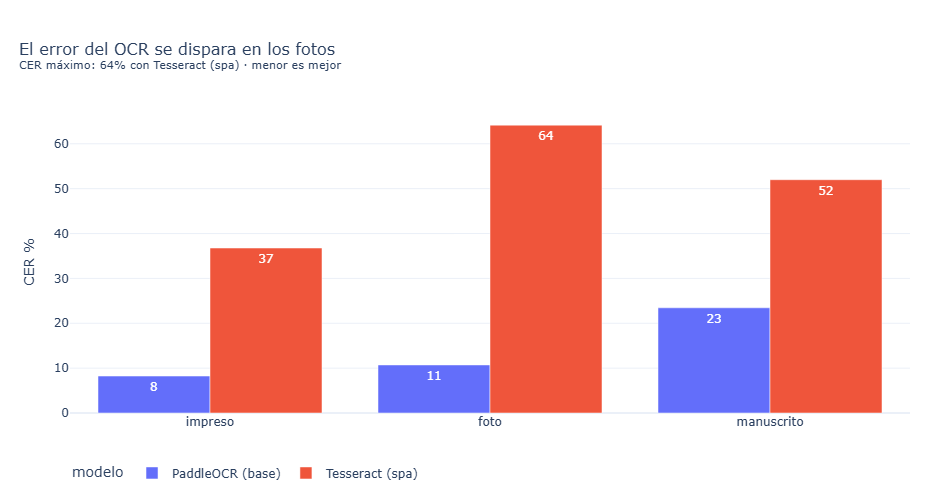

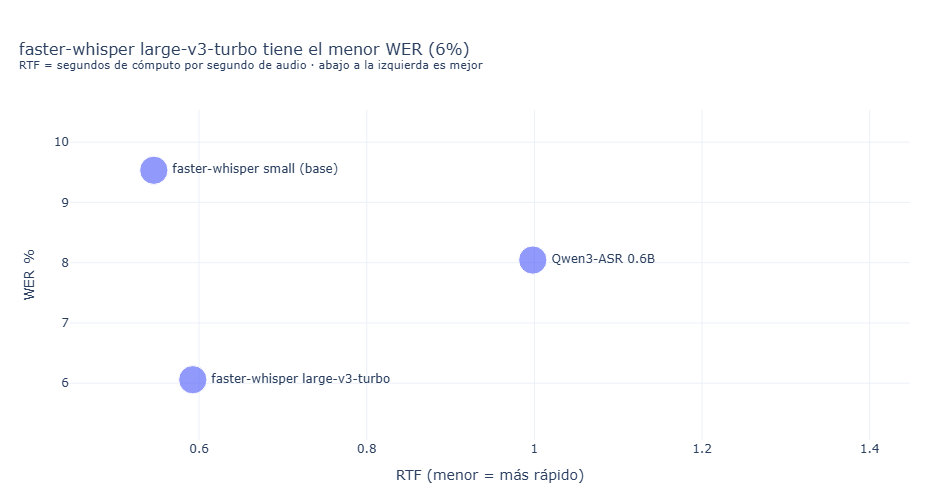

In [24]:
def mostrar(fig):
    fig.update_layout(template="plotly_white", title_x=0.02,
                      margin=dict(t=110, l=70, r=40, b=60), title_font_size=16)
    fig.show()
    try:
        from IPython.display import Image as PNG
        display(PNG(fig.to_image(format="png", width=950, height=500)))
    except Exception:
        pass

# 1) CER por tipo de documento y modelo de OCR
g = (tabla_ocr[["impreso", "foto", "manuscrito"]] * 100).reset_index().melt("modelo", var_name="tipo", value_name="CER %")
peor = g.loc[g["CER %"].idxmax()]
fig = px.bar(g, x="tipo", y="CER %", color="modelo", barmode="group", text_auto=".0f",
             title=(f"El error del OCR se dispara en los {peor.tipo}s<br>"
                    f"<sup>CER máximo: {peor['CER %']:.0f}% con {peor.modelo} · menor es mejor</sup>"))
fig.update_layout(xaxis_title="", legend=dict(orientation="h", y=-0.15))
mostrar(fig)

# 2) WER vs. velocidad de los modelos de ASR
h = comp_asr.groupby("modelo").agg(WER=("error", lambda s: wer_corpus(comp_asr.loc[s.index]) * 100),
                                   RTF=("rtf", "mean")).reset_index()
mejor = h.loc[h.WER.idxmin()]
fig = px.scatter(h, x="RTF", y="WER", text="modelo", size=[20] * len(h),
                 title=(f"{mejor.modelo} tiene el menor WER ({mejor.WER:.0f}%)<br>"
                        f"<sup>RTF = segundos de cómputo por segundo de audio · abajo a la izquierda es mejor</sup>"))
fig.update_traces(textposition="middle right")
fig.update_layout(xaxis_title="RTF (menor = más rápido)", yaxis_title="WER %",
                  xaxis_range=[h.RTF.min() - 0.1, h.RTF.max() + 0.45],
                  yaxis_range=[h.WER.min() - 1, h.WER.max() + 1])
mostrar(fig)

In [23]:
# Casos difíciles: los documentos y clips con más error para cada modelo
print("Documentos con mayor CER:")
display(comp_ocr.sort_values("error", ascending=False).head(6)[["id", "grupo", "modelo", "error"]])
print("Clips con mayor WER:")
display(comp_asr.sort_values("error", ascending=False).head(6)[["id", "grupo", "modelo", "error"]])
for i in comp_ocr.sort_values("error", ascending=False)["id"].unique()[:2]:
    print(f"\n── {i} · referencia:\n{leer_ref(i)[:300]}")
    for r in comp_ocr[comp_ocr.id == i].itertuples():
        print(f"── {r.modelo} (CER {r.error:.0%}):\n{r.texto[:300]}")

Documentos con mayor CER:


,id,grupo,modelo,error
3,doc_002,impreso,Tesseract (spa),1.000000
9,doc_015,foto,Tesseract (spa),1.000000
11,doc_016,foto,Tesseract (spa),0.852071
1,doc_008,impreso,Tesseract (spa),0.779703
17,doc_025,manuscrito,Tesseract (spa),0.693694
13,doc_024,manuscrito,Tesseract (spa),0.621560


Clips con mayor WER:


,id,grupo,modelo,error
21,clip_002,Wikimedia Commons,Qwen3-ASR 0.6B,0.720000
2,clip_002,Wikimedia Commons,faster-whisper small (base),0.600000
3,clip_002,Wikimedia Commons,faster-whisper large-v3-turbo,0.560000
0,clip_007,Wikimedia Commons,faster-whisper small (base),0.350000
20,clip_007,Wikimedia Commons,Qwen3-ASR 0.6B,0.275000
22,clip_004,Wikimedia Commons,Qwen3-ASR 0.6B,0.169643



── doc_002 · referencia:
XX                           20
LA REPÚBLICA DEL PERÚ
PAGARÁ AL PORTADOR
Veinte Soles                 Veinte Soles

B322426                      B322426
Conforme a lo                dispuesto en las 
leyes de 27 de enero          y 4 de febrero de 1879
POR LA JUNTA                 ADMINISTRADORA
Y D
── PaddleOCR (base) (CER 44%):
RepiblicadelPeru
20
PORTADOR
PAGARÁ AL
B322426
B322426
VeinteSoles
NeinteSoles
leyes de2rdeEncro
y4deTebreodes879.
PORLAJUNTA
Y DE VIJILANCIA DE
ADMINISTRADORA
LAEMISION FISCAL
LIMA JUNIO 30 DE 1879.
── Tesseract (spa) (CER 100%):


── doc_015 · referencia:
MUNICIPALIDAD
DE JESUS MARIA
PERENNIZANDO LA
VISITA DE S.S.INAGURO EL
"PARQUE JUAN PABLO II"
SIENDO ALCALDE EL
ING. MIGUEL FORT MAGOT
Y REGIDORES:
            FEBRERO – 1988
 
EL ACTUAL CONCEJO MUNICIPAL EN 
RECUERDO DE SU SEGUNDA VISITA 
REMODELA EL PARQUE Y COLOCA LA
"GRAN CRUZ ORNAMENTAL"
SIENDO 
── PaddleOCR (base) (CER 7%):
MUNICIPALIDAD
DEJESUSMARIA
PERENNIZANDOLA
VISITA-DE-S

### Casos difíciles: errores observados y sus causas

**OCR**
- **doc_002 (billete de 1879):** Tesseract no devolvió nada (CER 100 %). PaddleOCR leyó casi todo, pero **pegó las palabras** ("VeinteSoles", "PORLAJUNTA", "y4deTebreodes879") y confundió letras parecidas ("Repiblica", "Neinte", "Encro"). *Causa:* las tipografías ornamentales, el fondo con grabados y las letras muy juntas. Además, los espacios que faltan también cuentan como error en el CER.
- **doc_015 (placa de parque):** Tesseract obtuvo CER 100 %. *Causa:* las letras están en relieve, del mismo color que la placa, y tienen brillo del sol, así que no hay contraste entre el texto y el fondo.
- **doc_016 (cartel #ModoNiñez):** Tesseract obtuvo CER 85 %. *Causa:* la sombra de hojas sobre el cartel y la letra cursiva.
- **Manuscritos (doc_024, doc_025):** CER de 62–69 % con Tesseract. *Causa:* Tesseract está entrenado con letra impresa y no reconoce la escritura a mano ni las letras unidas.

**ASR**
- **clip_002 (entrevista en la calle, El Agustino):** es el peor clip para los tres modelos (WER 56–72 %). *Causa:* el ruido de la calle, voces superpuestas y habla espontánea con frases cortadas. En comparación, la voz leída de OpenSLR tiene un WER cercano a 0.
- **clip_007:** también es una entrevista real; small y Qwen3-ASR fallan más que turbo.

**Patrón general:** el error depende más de **las condiciones del documento o del audio** (tipografía, contraste, ruido, espontaneidad) que de su contenido.

### Decisión

| Modalidad | Modelo elegido | Por qué |
|---|---|---|
| Documentos | **PaddleOCR** | CER 14 % frente a 49% de Tesseract (≈3.5 veces más preciso). Es más lento en CPU, pero para un archivo histórico importa más la precisión que la velocidad |
| Audio | **faster-whisper large-v3-turbo** | Tiene el menor WER (6 %) y es más rápido que el tiempo real (RTF ≈ 0.6). Qwen3-ASR empata en voz leída, pero falla más en entrevistas y es más lento (RTF ≈ 1). Small es apenas más rápido y comete más errores (≈ 9.5 %) |
| Extracción | **LLM local (qwen2.5:3b, Ollama)** | Coincide con la auditoría humana en 5/20 casos. Sirve para organizar, no para confiar sin revisión: casi no inventa datos, pero omite muchos. Para producción convendría un modelo más grande o revisión humana obligatoria |

**Respuesta a la pregunta de la tarea:** sí, se pueden convertir documentos y audios en texto buscable. La calidad es buena con impresos limpios y voz clara, pero **los manuscritos, las fotos en la calle y las entrevistas con ruido siguen necesitando revisión humana**.